# 1. RNN od zera

**Teoria do tego notebooka:** [`01_rnn.md`](01_rnn.md)

Plan:

1. komórka RNN od zera i sprawdzenie, że liczy to samo co `torch.nn.RNN`,
2. znakowy model języka na RNN: trening na "Panu Tadeuszu" i generowanie **ze stanem**,
3. dlaczego sekwencyjność boli: te same obliczenia jako T małych mnożeń vs jedno duże,
4. znikający i eksplodujący gradient: pomiar na żywo,
5. przycinanie gradientu w praktyce,
6. zadanie pamięciowe: na jaką odległość RNN potrafi coś zapamiętać?

In [1]:
import math

import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from common import (MEMORY_VOCAB, count_params, load_results, plot_memory, prepare_data,
                    run_memory_experiment, sample_from_logits, save_results, set_seed, time_fn,
                    train, TrainConfig)

plt.rcParams["figure.dpi"] = 110
tok, train_data, val_data = prepare_data()

## 1. Komórka RNN

$$h_t = \tanh(x_t W_{xh} + h_{t-1} W_{hh} + b)$$

(piszemy wektory jako wiersze, bo w PyTorch batch jest pierwszym wymiarem: `x_t` ma kształt `(B, input_size)`).

Zwróć uwagę na podział w `forward`:
- `x @ W_xh` liczymy **od razu dla wszystkich kroków** jednym mnożeniem (wejście znamy z góry),
- `h @ W_hh` musi iść **w pętli**, bo potrzebuje `h` z poprzedniego kroku.

In [2]:
class RNN(nn.Module):
    """Elman RNN: h_t = tanh(x_t W_xh + h_{t-1} W_hh + b)."""

    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        bound = 1 / math.sqrt(hidden_size)
        self.W_xh = nn.Parameter(torch.empty(input_size, hidden_size).uniform_(-bound, bound))
        self.W_hh = nn.Parameter(torch.empty(hidden_size, hidden_size).uniform_(-bound, bound))
        self.b = nn.Parameter(torch.zeros(hidden_size))

    def forward(self, x, h=None):
        """x: (B, T, input_size) -> (wszystkie stany (B, T, H), ostatni stan (B, H))."""
        if h is None:
            h = x.new_zeros(x.shape[0], self.hidden_size)
        xw = x @ self.W_xh + self.b
        hs = []
        # unbind zamiast xw[:, t]: indeksowanie w pętli kazałoby autogradowi tworzyć pełny tensor gradientu w każdym kroku
        for xw_t in xw.unbind(dim=1):
            h = torch.tanh(xw_t + h @ self.W_hh)
            hs.append(h)
        return torch.stack(hs, dim=1), h

Sprawdźmy, że to jest dokładnie to, co liczy `torch.nn.RNN`. PyTorch trzyma wagi transponowane i ma dwa biasy
($b_{ih} + b_{hh}$), więc kopiujemy je odpowiednio.

In [3]:
set_seed(0)
ref = nn.RNN(input_size=8, hidden_size=16, batch_first=True)
ours = RNN(8, 16)
with torch.no_grad():
    ours.W_xh.copy_(ref.weight_ih_l0.T)
    ours.W_hh.copy_(ref.weight_hh_l0.T)
    ours.b.copy_(ref.bias_ih_l0 + ref.bias_hh_l0)

x = torch.randn(4, 10, 8)
out_ours, h_ours = ours(x)
out_ref, h_ref = ref(x)
print("max różnica wyjść:", (out_ours - out_ref).abs().max().item())

max różnica wyjść: 1.1920928955078125e-07


## 2. Znakowy model języka na RNN

"Kanapka" z rozdziału 0: embedding → RNN → warstwa wyjściowa.

In [4]:
class CharRNN(nn.Module):
    def __init__(self, vocab_size, emb_dim=64, hidden_size=512):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim)
        self.rnn = RNN(emb_dim, hidden_size)
        self.head = nn.Linear(hidden_size, vocab_size)

    def forward(self, idx, h=None, return_state=False):
        out, h = self.rnn(self.emb(idx), h)
        logits = self.head(out)
        return (logits, h) if return_state else logits


set_seed(1337)
model = CharRNN(tok.vocab_size)
print(f"parametry: {count_params(model):,}".replace(",", " "))

parametry: 345 623


Wspólne ustawienia treningu dla wszystkich modeli w tutorialu: 1000 kroków, batch 32 × okno 128 znaków,
AdamW, rozgrzewka + cosinus, **przycinanie gradientu do normy 1**. Trwa to ok. minuty na CPU.

In [5]:
cfg = TrainConfig(lr=4e-3)
hist = train(model, train_data, val_data, cfg)

krok     0 | train   -   | val 4.478 |    0.0s


krok   100 | train 2.930 | val 2.348 |    5.7s


krok   200 | train 2.172 | val 2.098 |   11.4s


krok   300 | train 1.961 | val 1.975 |   17.2s


krok   400 | train 1.850 | val 1.920 |   22.9s


...

krok   600 | train 1.705 | val 1.846 |   34.2s


krok   700 | train 1.649 | val 1.821 |   40.0s


krok   800 | train 1.608 | val 1.805 |   45.8s


krok   900 | train 1.572 | val 1.796 |   51.5s


krok  1000 | train 1.547 | val 1.792 |   57.2s


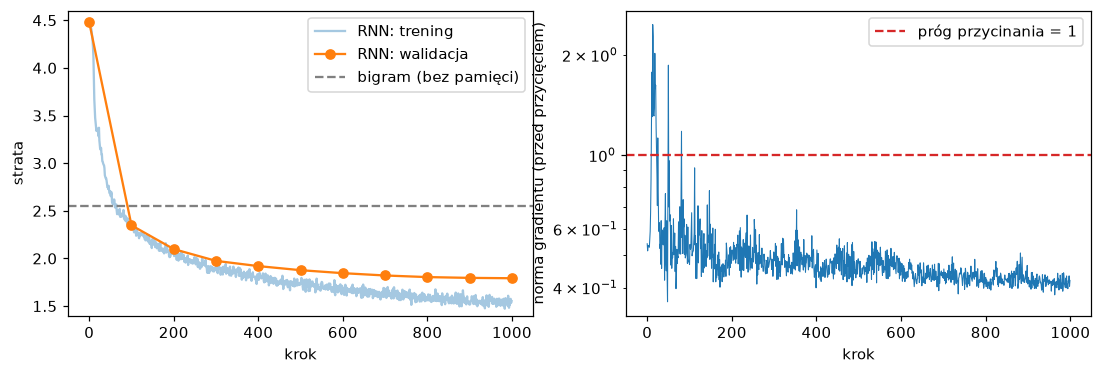

końcowa strata walidacyjna: 1.792, 57 ms/krok


In [6]:
bigram = load_results("00_bigram")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(hist["train_loss"], alpha=0.4, label="RNN: trening")
axes[0].plot(hist["eval_step"], hist["val_loss"], "o-", label="RNN: walidacja")
if bigram:
    axes[0].axhline(bigram["val_loss"][-1], color="gray", ls="--", label="bigram (bez pamięci)")
axes[0].set_ylim(1.4, 4.6)
axes[0].set_xlabel("krok")
axes[0].set_ylabel("strata")
axes[0].legend()
axes[1].plot(hist["grad_norm"], lw=0.7)
axes[1].axhline(cfg.grad_clip, color="C3", ls="--", label="próg przycinania = 1")
axes[1].set_yscale("log")
axes[1].set_xlabel("krok")
axes[1].set_ylabel("norma gradientu (przed przycięciem)")
axes[1].legend()
plt.show()
print(f"końcowa strata walidacyjna: {hist['val_loss'][-1]:.3f}, {hist['sec_per_step'] * 1000:.0f} ms/krok")

Prawy wykres pokazuje, po co jest **przycinanie gradientu**: na początku treningu, gdy wagi są jeszcze przypadkowe,
norma gradientu kilka razy wyskakuje wyraźnie ponad próg. Bez przycinania taki skok oznacza jeden za duży krok,
który potrafi zepsuć wagi. Potem trening się uspokaja i przycinanie prawie nie jest potrzebne.

### Generowanie ze stanem

RNN nie musi przy każdym znaku czytać całego tekstu od nowa: przetwarza prompt raz, dostaje stan $h$,
a potem karmi się **jednym** znakiem naraz. Koszt każdego kroku jest stały.

In [7]:
@torch.no_grad()
def generate_rnn(model, prompt, n_new, temperature=0.8, seed=0):
    model.eval()
    g = torch.Generator().manual_seed(seed)
    idx = torch.tensor([tok.encode(prompt)])
    logits, h = model(idx, return_state=True)
    out = idx[0].tolist()
    for _ in range(n_new):
        nxt = sample_from_logits(logits[:, -1], temperature, generator=g)
        out.append(nxt.item())
        logits, h = model(nxt, h, return_state=True)
    model.train()
    return tok.decode(out)


sample = generate_rnn(model, "Litwo! Ojczyzno moja! ", 400)
print(sample)

Litwo! Ojczyzno moja! tym podobadę, lecz widziała, znakiem: przekrót świadkie. Tadeusz spod kamieniu
Na łowę szlachcic podźwiłowiedzi,
Aby w niej, pośpodusz miał przyciszkie głowy; Dróżnie pod Podkomorzego mnie wspomnienie, znowu miał, że wolna na ciężką stare,
U równinami bezpiecznie
On stał i ubrany nad odcieży — prością zwał z drabia, kto jesteś usługiej stronę i drugiem,
Że obwicia się w fiernej poryknął i ruszył n


In [8]:
save_results("01_rnn", {"name": "RNN", **hist, "sample": sample})

PosixPath('/home/womackow/CODE_SPACE/agh/sem2/UMISI-sem2-NN-Arch/RWKV/results/01_rnn.json')

## 3. Dlaczego sekwencyjność boli (nawet przy tej samej liczbie obliczeń)

Zróbmy dokładnie te same obliczenia na dwa sposoby:

- **sekwencyjnie**: T razy mnożenie `(B × d) @ (d × d)`, jak w pętli RNN,
- **naraz**: jedno mnożenie `(B·T × d) @ (d × d)`, jak w Transformerze (i jak w RWKV, zobaczymy w rozdziale 4).

Liczba operacji zmiennoprzecinkowych jest identyczna. Różni się tylko to, czy sprzęt dostaje jedno duże zadanie,
czy T małych, jedno po drugim. Mierzymy dla batcha 1 (jak przy generowaniu) i batcha 32 (jak w naszym treningu).

In [9]:
d = 512
W = torch.randn(d, d) / math.sqrt(d)
for B in (1, 32):
    for T in (128, 2048):
        X = torch.randn(B, T, d)
        t_seq = time_fn(lambda: [x_t @ W for x_t in X.unbind(1)], repeats=5)
        t_bat = time_fn(lambda: X.reshape(B * T, d) @ W, repeats=5)
        print(f"batch {B:2d}, T = {T:4d}: sekwencyjnie {t_seq * 1000:7.2f} ms | naraz {t_bat * 1000:6.2f} ms"
              f" | {t_seq / t_bat:4.1f}x")

batch  1, T =  128: sekwencyjnie    2.43 ms | naraz   0.23 ms | 10.7x


batch  1, T = 2048: sekwencyjnie   38.24 ms | naraz   2.38 ms | 16.1x
batch 32, T =  128: sekwencyjnie    5.72 ms | naraz   3.39 ms |  1.7x


batch 32, T = 2048: sekwencyjnie  145.61 ms | naraz 123.76 ms |  1.2x


- Przy **batchu 1** wersja sekwencyjna musi $T$ razy wczytać z pamięci całą macierz $W$, a wersja "naraz" tylko raz,
  więc różnica jest kilku-, kilkunastokrotna.
- Przy **batchu 32** na CPU różnica jest umiarkowana, bo mnożenie 32 × 512 × 512 i tak dobrze zajmuje kilka rdzeni CPU.
  Na GPU takie małe mnożenie wykorzystuje ułamek tysięcy rdzeni, więc tam różnica rośnie o rząd wielkości.
- Najważniejszego ten pomiar nie pokazuje: w prawdziwym RNN krok $t$ **nie może się nawet zacząć**, dopóki nie skończy
  się krok $t-1$. Dołożenie sprzętu nie przyspieszy więc pętli po czasie. W Transformerze (i w RWKV) przyspieszy.

## 4. Znikający i eksplodujący gradient: pomiar

Mierzymy, jak mocno stan końcowy $h_T$ zależy od wejścia sprzed $n$ kroków:
$\left\lVert \partial h_T / \partial x_{T-n} \right\rVert$.
Bierzemy RNN z macierzą $W_{hh} = \rho \cdot Q$, gdzie $Q$ jest ortogonalna,
więc wszystkie wartości singularne $W_{hh}$ są równe $\rho$.

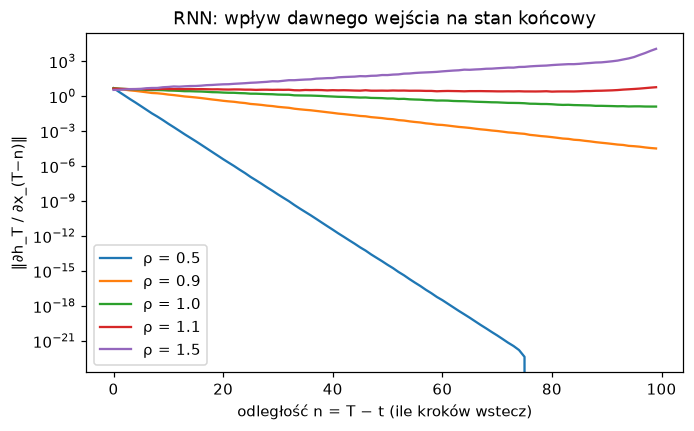

In [10]:
def input_gradient_norms(rnn, x):
    """||d(h_T · r)/d x_t|| dla każdego t, gdzie r to losowy kierunek (uśrednione po batchu)."""
    x = x.clone().requires_grad_(True)
    _, h_T = rnn(x)
    direction = torch.randn_like(h_T, generator=torch.Generator().manual_seed(0))
    (h_T * direction).sum().backward()
    return x.grad.norm(dim=-1).mean(0)


T, H = 100, 64
x = 0.1 * torch.randn(16, T, H, generator=torch.Generator().manual_seed(1))
fig, ax = plt.subplots(figsize=(7, 4))
for rho in (0.5, 0.9, 1.0, 1.1, 1.5):
    set_seed(0)
    rnn = RNN(H, H)
    with torch.no_grad():
        nn.init.orthogonal_(rnn.W_hh)
        rnn.W_hh.mul_(rho)
    g = input_gradient_norms(rnn, x)
    ax.semilogy(range(T), g.flip(0).detach(), label=f"ρ = {rho}")
ax.set_xlabel("odległość n = T − t (ile kroków wstecz)")
ax.set_ylabel("‖∂h_T / ∂x_(T−n)‖")
ax.set_title("RNN: wpływ dawnego wejścia na stan końcowy")
ax.legend()
plt.show()

Dokładnie jak w teorii (rozdział 1.4): dla $\rho < 1$ gradient spada wykładniczo (prosta na skali logarytmicznej),
dla $\rho > 1$ rośnie wykładniczo, dopóki tanh nie wejdzie w saturację. Tylko przy $\rho \approx 1$ sygnał
przeżywa dłużej, ale to jest stan "na ostrzu noża", który trening łatwo zaburza.

A jak daleko patrzy nasz **wytrenowany** model? Liczymy gradient straty na ostatniej pozycji okna
względem embeddingów wszystkich wcześniejszych znaków.

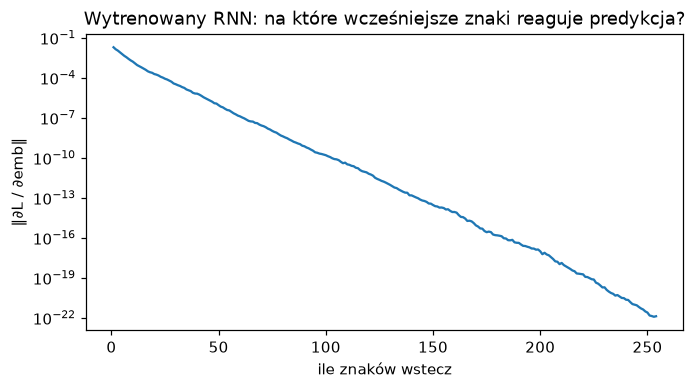

In [11]:
def context_sensitivity(model, idx):
    """||dL_ostatni / d emb(x_t)|| dla każdej pozycji t w oknie (uśrednione po batchu)."""
    emb = model.emb(idx).detach().requires_grad_(True)
    out, _ = model.rnn(emb)
    logits = model.head(out[:, -1])
    loss = nn.functional.cross_entropy(logits, idx[:, -1])
    loss.backward()
    return emb.grad.norm(dim=-1).mean(0)


g = torch.Generator().manual_seed(5)
starts = torch.randint(len(val_data) - 257, (64,), generator=g)
windows = torch.stack([val_data[s : s + 256] for s in starts])
sens = context_sensitivity(model, windows[:, :-1]).flip(0)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(range(1, len(sens)), sens[1:])
ax.set_xlabel("ile znaków wstecz")
ax.set_ylabel("‖∂L / ∂emb‖")
ax.set_title("Wytrenowany RNN: na które wcześniejsze znaki reaguje predykcja?")
plt.show()

Wpływ dalekich znaków spada o rzędy wielkości w ciągu kilkudziesięciu kroków. Trening przez BPTT
po prostu nie dostaje sygnału, żeby wykorzystać coś, co było dawno.

## 5. Zadanie pamięciowe

Syntetyczny test pamięci długiej (definicja w `common.py`):

`[KLUCZ, szum, szum, ..., szum, ?]` → model ma odpowiedzieć KLUCZEM na pozycji `?`.

Kluczy jest 8, więc zgadywanie daje 12,5%. Zwiększamy odległość $L$ między kluczem a pytaniem i patrzymy,
kiedy model przestaje sobie radzić. Ten sam protokół powtarzamy we wszystkich rozdziałach:

- dla każdego $L$ trenujemy **świeży, mały model** (embedding 32, stan 128), dwa razy z różnym seedem,
- limit to 1000 kroków po 64 przykłady; trening kończy się wcześniej, gdy model rozwiąże zadanie (≥ 99%),
- kropki na wykresie to pojedyncze seedy, linia to średnia.

Dla szybkości używamy tu `nn.RNN` (pętla w C++). W punkcie 1 sprawdziliśmy, że liczy dokładnie to samo
co nasza klasa `RNN`.

In [12]:
class TorchCharRNN(nn.Module):
    """CharRNN z nn.RNN zamiast naszej pętli w Pythonie: ta sama matematyka, kilka razy szybciej."""

    def __init__(self, vocab_size, emb_dim=32, hidden_size=128):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim)
        self.rnn = nn.RNN(emb_dim, hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, vocab_size)

    def forward(self, idx):
        return self.head(self.rnn(self.emb(idx))[0])


MEMORY_LENGTHS = [5, 10, 20, 40, 80]
memory = run_memory_experiment(lambda: TorchCharRNN(MEMORY_VOCAB), MEMORY_LENGTHS, name="RNN")
save_results("01_rnn_memory", memory)

L =    5: trafność 100% / 100%   kroki treningu:   67 /   64   (0 s)


L =   10: trafność 100% /  38%   kroki treningu:  206 / 1000   (2 s)


L =   20: trafność  45% /  11%   kroki treningu: 1000 / 1000   (6 s)


L =   40: trafność  14% /  13%   kroki treningu: 1000 / 1000   (10 s)


L =   80: trafność  27% /  11%   kroki treningu: 1000 / 1000   (19 s)


PosixPath('/home/womackow/CODE_SPACE/agh/sem2/UMISI-sem2-NN-Arch/RWKV/results/01_rnn_memory.json')

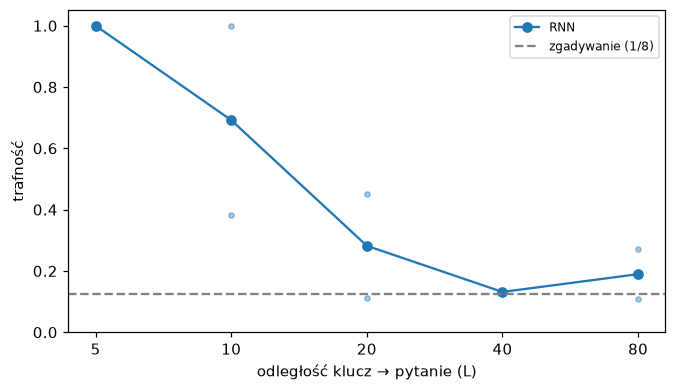

In [13]:
plot_memory([memory])
plt.show()

Dla krótkich odległości RNN rozwiązuje zadanie od ręki. Już przy kilkunastu–kilkudziesięciu krokach wyniki
stają się **loterią**: jeden seed się uczy, drugi utyka na poziomie zgadywania. Dokładnie tak, jak przewiduje
analiza gradientu z punktu 4: sygnał o kluczu dociera do wag osłabiony o rzędy wielkości.

## Podsumowanie

- RNN to kilkanaście linii kodu: równoległe `x @ W_xh` i sekwencyjna pętla po `h @ W_hh`.
- Na krótkim kontekście (znaki w wierszu) radzi sobie zaskakująco dobrze, a generowanie ze stanem
  ma stały koszt na znak.
- **Sekwencyjność**: T małych kroków zamiast jednego dużego mnożenia to (zależnie od batcha i sprzętu) od kilkudziesięciu
  procent do kilkunastu razy wolniej. A przede wszystkim pętli po czasie nie da się przyspieszyć, dokładając sprzętu.
- **Gradient** przez $n$ kroków skaluje się jak $\rho^n$: znika albo eksploduje. Przycinanie ratuje przed eksplozją,
  ale nie przed zanikiem, więc RNN przestaje "pamiętać" już po kilkudziesięciu krokach.

**Dalej:** [`02_lstm.md`](02_lstm.md) → [`02_lstm.ipynb`](02_lstm.ipynb)